# Microproyecto CNN — Clasificación de imágenes MRI cerebrales

## 1. Importaciones y rutas

In [1]:
from pathlib import Path
from collections import Counter
import random
import zipfile
import shutil

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)



Se utilizaron rutas relativas y una búsqueda automática de la carpeta raíz para que el proyecto sea reproducible en diferentes computadores, sin necesidad de modificar las rutas según el usuario o el sistema operativo. Para que funcione correctamente, se debe conservar la siguiente estructura: la carpeta Proyecto1 debe contener data, notebooks y results; dentro de data debe estar el archivo data.zip, mientras que el notebook debe guardarse en notebooks. El código crea automáticamente la carpeta mri_images y extrae allí las imágenes si todavía no existen. Es importante mantener esta organización de archivos para que el código encuentre los datos y guarde los resultados correctamente.

In [2]:
from pathlib import Path

INICIO = Path.cwd()

BASE = next(
    (
        p for p in (INICIO, *INICIO.parents, *INICIO.rglob("*"))
        if p.is_dir()
        and (
            (p / "data" / "data.zip").is_file()
            or (p / "data" / "mri_images").is_dir()
        )
    ),
    None
)

if BASE is None:
    raise FileNotFoundError(
        "No se encontró la carpeta del proyecto con los datos."
    )

RUTA_ZIP = BASE / "data" / "data.zip"
DIR_DATOS = BASE / "data" / "mri_images"
DIR_RESULTADOS = BASE / "results"

print("Proyecto encontrado:", BASE)

Proyecto encontrado: C:\Users\jsroj\OneDrive\Documentos\NevarYLLover\Maestria_IA\Deep_learning\Proyecto1


## Configuración general

In [3]:
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 15
CLASES = ["glioma", "healthy", "meningioma", "pituitary"]
NUM_CLASES = len(CLASES)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 2. Extraer imágenes y crear `rutas` y `etiquetas`

In [4]:
# Extraer imágenes si la carpeta no existe
if not DIR_DATOS.is_dir():
    if not RUTA_ZIP.is_file():
        raise FileNotFoundError(f"No se encontró el ZIP: {RUTA_ZIP}")

    DIR_DATOS.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(RUTA_ZIP, "r") as archivo:
        archivo.extractall(DIR_DATOS)

Se definieron cuatro clases correspondientes a las categorías del conjunto de imágenes MRI: `glioma`, `healthy`, `meningioma` y `pituitary`. Cada clase debe coincidir con el nombre de su carpeta dentro del directorio `mri_images`, ya que el código utiliza esta correspondencia para asignar automáticamente las etiquetas numéricas a las imágenes.

In [5]:
# Crear rutas y etiquetas
rutas, etiquetas = [], []

for indice, clase in enumerate(CLASES):
    carpeta = DIR_DATOS / clase

    if not carpeta.is_dir():
        raise FileNotFoundError(f"No existe la carpeta: {carpeta}")

    imagenes = sorted(
        p for p in carpeta.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    if not imagenes:
        raise ValueError(f"No hay imágenes en {carpeta}")

    rutas.extend(str(p) for p in imagenes)
    etiquetas.extend([indice] * len(imagenes))
    print(f"{clase}: {len(imagenes)} imágenes")

rutas = np.asarray(rutas)
etiquetas = np.asarray(etiquetas, dtype=np.int32)

print(f"Total de imágenes: {len(rutas)}")

glioma: 1621 imágenes
healthy: 2000 imágenes
meningioma: 1645 imágenes
pituitary: 1757 imágenes
Total de imágenes: 7023


In [6]:
for i in np.random.choice(len(rutas), size=8, replace=False):
    print(f"Etiqueta: {etiquetas[i]} | Clase: {CLASES[etiquetas[i]]} | Archivo: {Path(rutas[i]).name}")

Etiqueta: 2 | Clase: meningioma | Archivo: 0289.jpg
Etiqueta: 1 | Clase: healthy | Archivo: 0841.jpg
Etiqueta: 1 | Clase: healthy | Archivo: 1258.jpg
Etiqueta: 2 | Clase: meningioma | Archivo: 1600.jpg
Etiqueta: 3 | Clase: pituitary | Archivo: 1629.jpg
Etiqueta: 3 | Clase: pituitary | Archivo: 0186.jpg
Etiqueta: 1 | Clase: healthy | Archivo: 0552.jpg
Etiqueta: 1 | Clase: healthy | Archivo: 0855.jpg


## 3. Visualizar ejemplos

Mostramos dos imágenes de cada clase. Las distintas dimensiones originales se adaptarán al entrenar.

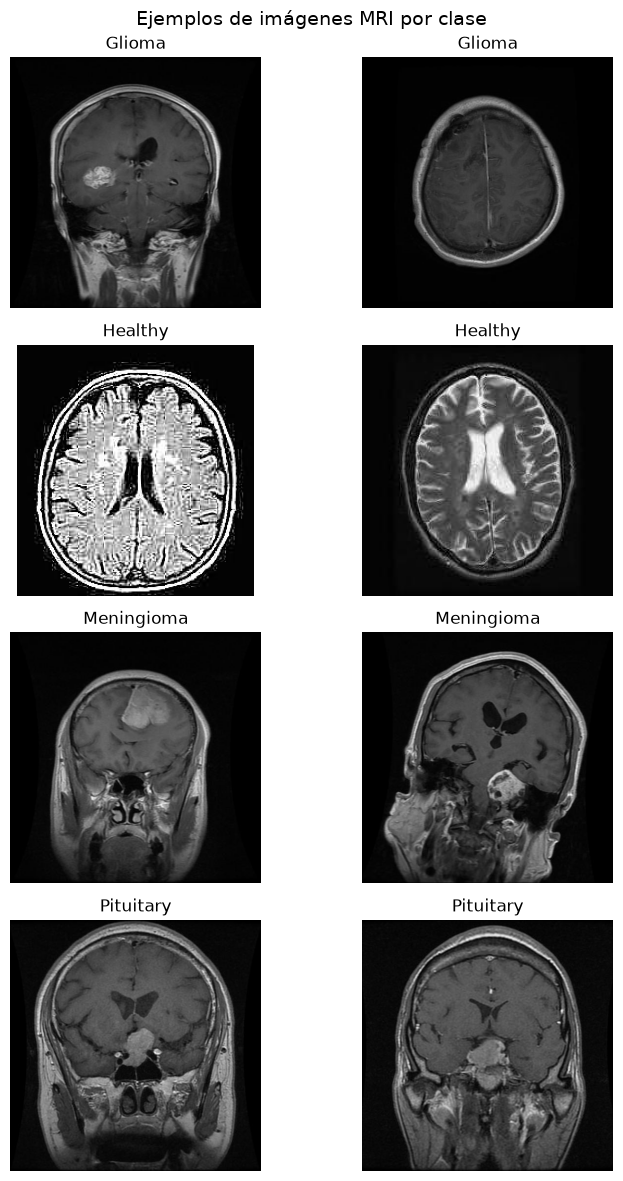

In [7]:
fig, ejes = plt.subplots(NUM_CLASES, 2, figsize=(8, 12))

for fila, clase in enumerate(CLASES):
    imagenes_clase = rutas[etiquetas == fila]
    indices = np.random.default_rng(SEED + fila).choice(
        len(imagenes_clase), size=2, replace=False
    )
    for columna, indice in enumerate(indices):
        with Image.open(imagenes_clase[indice]) as archivo:
            imagen = archivo.convert("RGB")
            ejes[fila, columna].imshow(imagen)
        ejes[fila, columna].set_title(clase.title())
        ejes[fila, columna].axis("off")

plt.suptitle("Ejemplos de imágenes MRI por clase", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Dividir el dataset en entrenamiento, validación y prueba

Separamos **70 % entrenamiento, 15 % validación y 15 % prueba**, manteniendo aproximadamente las proporciones de cada clase (`stratify`). Las imágenes de prueba **no se usan para entrenar ni escoger el modelo**.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    rutas,
    etiquetas,
    test_size=0.30,
    random_state=SEED,
    stratify=etiquetas,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp,
)

print(f"Entrenamiento: {len(X_train)} imágenes")
print(f"Validación:    {len(X_val)} imágenes")
print(f"Prueba:        {len(X_test)} imágenes")

assert set(X_train).isdisjoint(set(X_val))
assert set(X_train).isdisjoint(set(X_test))
assert set(X_val).isdisjoint(set(X_test))

print("\nDistribución por clase:")
for i, clase in enumerate(CLASES):
    print(
        f"{clase:12s} -> train: {(y_train == i).sum():4d} "
        f"| val: {(y_val == i).sum():4d} "
        f"| test: {(y_test == i).sum():4d}"
    )

## 5. Preparar las imágenes con `tf.data`

Convertimos cada imagen a **RGB**, redimensionamos a **128 × 128** píxeles y agrupamos en lotes de **32**. 

In [ ]:
def cargar_imagen(ruta, etiqueta):
    contenido = tf.io.read_file(ruta)
    imagen = tf.io.decode_jpeg(contenido, channels=3)
    imagen = tf.image.resize(imagen, (IMG_SIZE, IMG_SIZE))
    imagen = tf.cast(imagen, tf.float32)
    return imagen, etiqueta


def crear_dataset(rutas_archivos, labels, entrenando=False):
    ds = tf.data.Dataset.from_tensor_slices((rutas_archivos, labels))
    if entrenando:
        ds = ds.shuffle(
            buffer_size=len(rutas_archivos),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
    ds = ds.map(cargar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = crear_dataset(X_train, y_train, entrenando=True)
val_ds = crear_dataset(X_val, y_val)
test_ds = crear_dataset(X_test, y_test)

imagenes_lote, etiquetas_lote = next(iter(train_ds))
print("Dimensión del lote:", imagenes_lote.shape)
print("Etiquetas del lote:", etiquetas_lote.shape)
print("Rango de los píxeles:", float(tf.reduce_min(imagenes_lote)),
      "a", float(tf.reduce_max(imagenes_lote)))

## 6. Construir una CNN

La arquitectura combina cuatro bloques de **convolución + normalización + max pooling**, seguidos de una capa densa y una salida `softmax` de cuatro clases. 

In [ ]:
from tensorflow.keras import layers, models

modelo = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Aumento de datos (se aplica solamente durante entrenamiento).
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
    layers.Rescaling(1.0 / 255.0),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASES, activation="softmax"),
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

modelo.summary()

## 7. Entrenar el modelo

Se entrenan como máximo **15 épocas**. 

In [ ]:
RUTA_MODELO = DIR_RESULTADOS / "mejor_modelo_mri.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(RUTA_MODELO),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1,
    ),
]

historial = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

# Para evaluar el mejor checkpoint guardado.
modelo = tf.keras.models.load_model(RUTA_MODELO)
print("Mejor modelo guardado en:", RUTA_MODELO)

## 8. Graficar la evolución del entrenamiento

Comparamos la **exactitud** y la **pérdida** de entrenamiento frente a validación para identificar señales de sobreajuste.

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(historial.history["accuracy"], label="Entrenamiento")
ejes[0].plot(historial.history["val_accuracy"], label="Validación")
ejes[0].set_title("Exactitud por época")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Accuracy")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

ejes[1].plot(historial.history["loss"], label="Entrenamiento")
ejes[1].plot(historial.history["val_loss"], label="Validación")
ejes[1].set_title("Pérdida por época")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Loss")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150)
plt.show()

## 9. Evaluar el modelo con el conjunto de prueba

Calculamos `accuracy`, **precision**, **recall**, **F1-score** y **matriz de confusión** utilizando exclusivamente las imágenes reservadas para prueba. 

In [ ]:
perdida_test, accuracy_test = modelo.evaluate(test_ds, verbose=1)
probabilidades_test = modelo.predict(test_ds, verbose=0)
predicciones_test = np.argmax(probabilidades_test, axis=1)

reporte = classification_report(
    y_test,
    predicciones_test,
    labels=np.arange(NUM_CLASES),
    target_names=CLASES,
    digits=4,
    zero_division=0,
)

print(f"Exactitud en prueba: {accuracy_test:.2%}")
print(f"Pérdida en prueba:  {perdida_test:.4f}")
print("\nReporte de clasificación:\n")
print(reporte)

texto_reporte = (
    f"Exactitud en prueba: {accuracy_test:.4f}\n"
    f"Pérdida en prueba: {perdida_test:.4f}\n\n"
    + reporte
)
(DIR_RESULTADOS / "reporte_clasificacion.txt").write_text(
    texto_reporte,
    encoding="utf-8",
)

## 10. Matriz de confusión

La diagonal contiene los aciertos de cada categoría; las celdas fuera de la diagonal muestran confusiones entre clases.

In [ ]:
matriz = confusion_matrix(
    y_test,
    predicciones_test,
    labels=np.arange(NUM_CLASES),
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=CLASES,
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=True)
ax.set_title("Matriz de confusión — conjunto de prueba")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(DIR_RESULTADOS / "matriz_confusion.png", dpi=150)
plt.show()

## 11. Predicción con una imagen

Usamos una imagen del **conjunto de prueba** para comprobar el funcionamiento. 
IMPORTANTE: El porcentaje mostrado es una **puntuación del modelo**; no equivale a una probabilidad clínica de tener cáncer.

In [ ]:
RUTA_NUEVA = Path(X_test[0])  # Sustituye por otra ruta si lo deseas
print("Imagen:", RUTA_NUEVA)

with Image.open(RUTA_NUEVA) as archivo:
    imagen = archivo.convert("RGB").resize((IMG_SIZE, IMG_SIZE))

tensor = tf.keras.utils.img_to_array(imagen)[None, ...]
probabilidades = modelo.predict(tensor, verbose=0)[0]
indice_predicho = int(np.argmax(probabilidades))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].imshow(imagen)
ejes[0].set_title(f"Clase predicha: {CLASES[indice_predicho]}")
ejes[0].axis("off")

ejes[1].barh(CLASES, probabilidades * 100)
ejes[1].set_xlim(0, 100)
ejes[1].set_xlabel("Puntuación softmax (%)")
ejes[1].set_title("Puntuaciones por categoría")
ejes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"Predicción: {CLASES[indice_predicho]}")
print(f"Puntuación del modelo: {probabilidades[indice_predicho]:.2%}")